# Customer-Level Churn Prediction Explanations

## Objective

Explain individual predictions from the saved enriched CatBoost churn model.

Target:
- 1: No observed purchase during the following 90 days.
- 0: At least one observed purchase during that period.

We will examine which features raise or lower the model's prediction
relative to its reference value.

Explanations describe model behavior and associations. They do not establish
why a customer stopped purchasing or whether a retention action will work.

The saved model and its recorded feature order will be used without retraining.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import catboost

current_folder = Path.cwd().resolve()

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (
            folder / "models" / "churn_enriched"
            / "catboost_churn_enriched.cbm"
        ).is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the saved CatBoost model. "
        "Open this notebook inside your project folder."
    )

churn_model_dir = project_root / "models" / "churn_enriched"
churn_model_path = churn_model_dir / "catboost_churn_enriched.cbm"
churn_metadata_path = (
    churn_model_dir / "catboost_churn_enriched_metadata.json"
)
explanation_data_path = (
    project_root / "data" / "processed"
    / "customer_churn_enriched_2020-03-31.parquet"
)

for path in [
    churn_model_path,
    churn_metadata_path,
    explanation_data_path
]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

explanation_report_dir = project_root / "reports" / "churn_explanations"
explanation_report_dir.mkdir(parents=True, exist_ok=True)

churn_metadata = json.loads(
    churn_metadata_path.read_text(encoding="utf-8")
)

explanation_model = catboost.CatBoostClassifier()
explanation_model.load_model(str(churn_model_path))

print("Python:", sys.executable)
print("CatBoost version:", catboost.__version__)
print("Model loaded:", churn_model_path.name)
print("Metadata keys:", sorted(churn_metadata.keys()))
print("Model class labels:", explanation_model.classes_)
print("Model feature count:", len(explanation_model.feature_names_))

display(pd.DataFrame({
    "position": range(len(explanation_model.feature_names_)),
    "model_feature_name": explanation_model.feature_names_
}))

# Inspect the saved dataset without loading all customers into memory.
with duckdb.connect() as inspection_con:
    dataset_schema = inspection_con.execute(
        "DESCRIBE SELECT * FROM read_parquet(?)",
        [str(explanation_data_path)]
    ).df()

display(dataset_schema)

print("Explanation reports folder:", explanation_report_dir)

Python: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
CatBoost version: 1.2.10
Model loaded: catboost_churn_enriched.cbm
Metadata keys: ['decision_threshold', 'feature_dtype', 'feature_names_in_order', 'feature_preprocessing', 'limitations', 'model_file', 'model_name', 'positive_class', 'prediction_horizon_days', 'target', 'target_definition', 'temporal_validation', 'training_feature_cutoff', 'training_outcome_end', 'training_rows', 'versions']
Model class labels: [0 1]
Model feature count: 26


,position,model_feature_name
0,0,transaction_records
1,1,purchase_days
2,2,distinct_articles
3,3,historical_spending
4,4,average_record_price
5,5,customer_history_days
6,6,active_months
7,7,purchase_days_last_30d
8,8,purchase_days_last_90d
9,9,purchase_days_last_180d


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,transaction_records,BIGINT,YES,None,None,None
2,purchase_days,BIGINT,YES,None,None,None
3,distinct_articles,BIGINT,YES,None,None,None
4,historical_spending,DOUBLE,YES,None,None,None
5,average_record_price,DOUBLE,YES,None,None,None
6,customer_history_days,BIGINT,YES,None,None,None
7,active_months,BIGINT,YES,None,None,None
8,purchase_days_last_30d,BIGINT,YES,None,None,None
9,purchase_days_last_90d,BIGINT,YES,None,None,None


Explanation reports folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\churn_explanations


## 1. Computing and Verifying SHAP Explanations

Use a reproducible sample of 500 customers from the saved historical dataset.
Sampling does not depend on the future outcome or predicted risk.

Load predictors in the saved model's feature order, using float32 inputs
consistent with the saved churn-scoring workflow.

For this binary classifier:
- Positive SHAP contributions increase predicted no-purchase risk.
- Negative contributions decrease predicted no-purchase risk.
- Contributions are expressed in log-odds, not percentage points.

Verify that the reference value plus all feature contributions reconstructs
the raw model output, and that its sigmoid matches the predicted probability.

Explanations describe the fitted model. They do not establish causal effects.

,sampled_customers,predictors,missing_predictor_values,max_raw_reconstruction_difference,max_probability_reconstruction_difference
0,500,26,0,6.217249e-15,7.771561e-16


,feature,mean_absolute_shap
15,recency_days,0.2651
10,purchase_days_last_365d,0.1879
6,active_months,0.1749
17,average_gap_days,0.1373
9,purchase_days_last_180d,0.1350
1,purchase_days,0.1247
13,customer_age,0.1027
16,completed_purchase_gaps,0.0873
20,purchase_days_recent_90d,0.0769
18,median_gap_days,0.0723


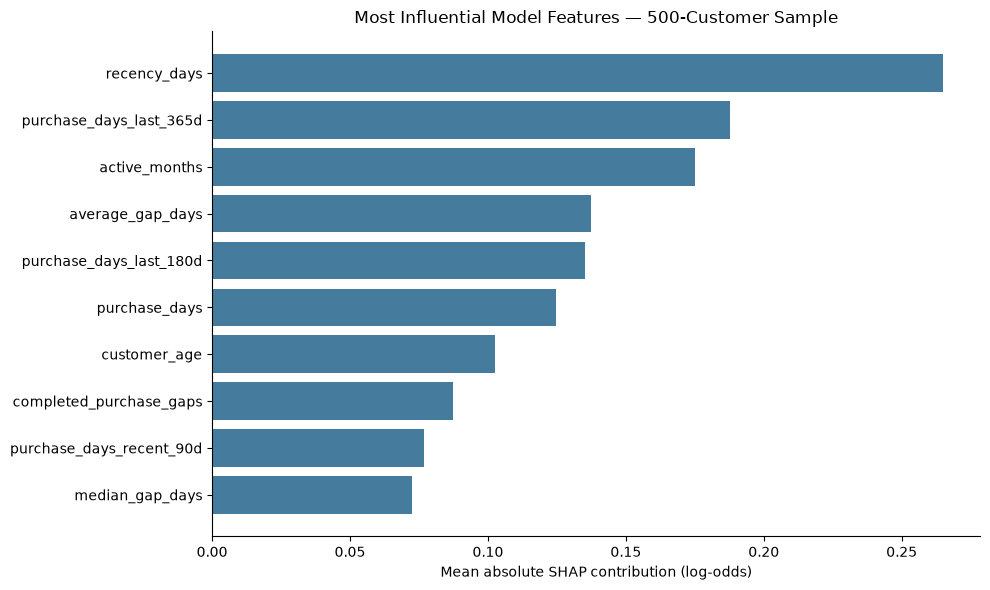

PASS: SHAP contributions reconstruct the model predictions.


In [2]:
from catboost import Pool
from scipy.special import expit

# 1. Validate feature names and class direction.
explanation_features = list(explanation_model.feature_names_)
dataset_columns = set(dataset_schema["column_name"])

missing_features = [
    feature for feature in explanation_features
    if feature not in dataset_columns
]

if missing_features:
    raise ValueError(f"Model features missing from dataset: {missing_features}")

assert len(explanation_features) == 26
assert len(set(explanation_features)) == 26
assert "customer_id" not in explanation_features
assert "churn_90d" not in explanation_features

if list(explanation_model.classes_) != [0, 1]:
    raise ValueError(
        "Unexpected class order. Check label definitions before interpreting SHAP."
    )

# 2. Select a deterministic sample without using outcomes.
# MD5 is used only for reproducible ordering, not for anonymization.
with duckdb.connect() as sample_con:
    explanation_sample = sample_con.execute("""
        SELECT *
        FROM read_parquet(?)
        ORDER BY MD5(customer_id), customer_id
        LIMIT 500
    """, [str(explanation_data_path)]).df()

assert explanation_sample["customer_id"].notna().all()
assert explanation_sample["customer_id"].is_unique

X_explain = explanation_sample[explanation_features].astype("float32")

assert not X_explain.isna().any().any()
assert np.isfinite(X_explain.to_numpy()).all()

explanation_pool = Pool(
    X_explain,
    feature_names=explanation_features
)

# 3. Obtain probabilities, raw scores, and native SHAP contributions.
no_purchase_probability = explanation_model.predict_proba(
    explanation_pool,
    thread_count=2
)[:, 1]

raw_model_output = np.asarray(
    explanation_model.predict(
        explanation_pool,
        prediction_type="RawFormulaVal",
        thread_count=2
    )
).reshape(-1)

shap_output = np.asarray(
    explanation_model.get_feature_importance(
        explanation_pool,
        type="ShapValues",
        thread_count=2
    )
)

assert shap_output.shape == (
    len(X_explain), len(explanation_features) + 1
)
assert np.isfinite(shap_output).all()

feature_contributions = shap_output[:, :-1]
reference_values = shap_output[:, -1]

reconstructed_raw = (
    reference_values + feature_contributions.sum(axis=1)
)
reconstructed_probability = expit(reconstructed_raw)

# 4. Verify the explanation mathematically.
raw_difference = np.abs(reconstructed_raw - raw_model_output)
probability_difference = np.abs(
    reconstructed_probability - no_purchase_probability
)

np.testing.assert_allclose(
    reconstructed_raw, raw_model_output,
    rtol=1e-6, atol=1e-6
)
np.testing.assert_allclose(
    reconstructed_probability, no_purchase_probability,
    rtol=1e-6, atol=1e-6
)

shap_verification = pd.DataFrame([{
    "sampled_customers": len(X_explain),
    "predictors": len(explanation_features),
    "missing_predictor_values": int(X_explain.isna().sum().sum()),
    "max_raw_reconstruction_difference": raw_difference.max(),
    "max_probability_reconstruction_difference": probability_difference.max(),
}])

display(shap_verification)

# 5. Summarize which features most influence predictions in this sample.
shap_sample_importance = pd.DataFrame({
    "feature": explanation_features,
    "mean_absolute_shap": np.abs(feature_contributions).mean(axis=0)
}).sort_values("mean_absolute_shap", ascending=False)

display(shap_sample_importance.head(10).round(4))

plot_data = shap_sample_importance.head(10).sort_values(
    "mean_absolute_shap"
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    plot_data["feature"],
    plot_data["mean_absolute_shap"],
    color="#457B9D"
)
ax.set_title("Most Influential Model Features — 500-Customer Sample")
ax.set_xlabel("Mean absolute SHAP contribution (log-odds)")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    explanation_report_dir / "sample_shap_feature_importance.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

shap_verification.to_csv(
    explanation_report_dir / "shap_reconstruction_check.csv",
    index=False
)
shap_sample_importance.to_csv(
    explanation_report_dir / "sample_shap_feature_importance.csv",
    index=False
)

print("PASS: SHAP contributions reconstruct the model predictions.")

## 2. Explaining an Individual Customer Prediction

Select the highest predicted-risk customer within the 500-customer sample.
This is an illustrative case, not a representative customer.

Display the ten largest absolute feature contributions.
Combine the remaining contributions into "Other features" so the explanation
retains the complete prediction.

- Positive contributions increase predicted no-purchase risk.
- Negative contributions decrease predicted no-purchase risk.
- Contributions are in log-odds, not probability percentage points.

The reference value plus all contributions reconstructs the raw prediction.
Applying the sigmoid function produces the predicted probability.

Customer age comes from the supplied customer snapshot; its availability
at the historical cutoff was not established. This limits historical
interpretation of age-related contributions.

Example: highest predicted-risk customer in the sample
Historical feature cutoff: 2020-03-31
Predicted probability of no purchase in the next 90 days: 97.55%
Sigmoid of SHAP reference value: 69.65%
The reference above is a transformed model reference, not necessarily the average customer probability.


,feature,feature_value,shap_log_odds,effect
0,recency_days,463.0,0.6818,Raises predicted risk
1,age_was_missing,1.0,0.5336,Raises predicted risk
2,purchase_days_last_365d,0.0,0.2170,Raises predicted risk
3,average_gap_days,0.0,0.1663,Raises predicted risk
4,active_months,1.0,0.1576,Raises predicted risk
5,purchase_days_last_180d,0.0,0.1322,Raises predicted risk
6,median_gap_days,0.0,0.1261,Raises predicted risk
7,purchase_days,1.0,0.1032,Raises predicted risk
8,customer_age,32.0,0.0930,Raises predicted risk
9,customer_history_days,464.0,0.0906,Raises predicted risk


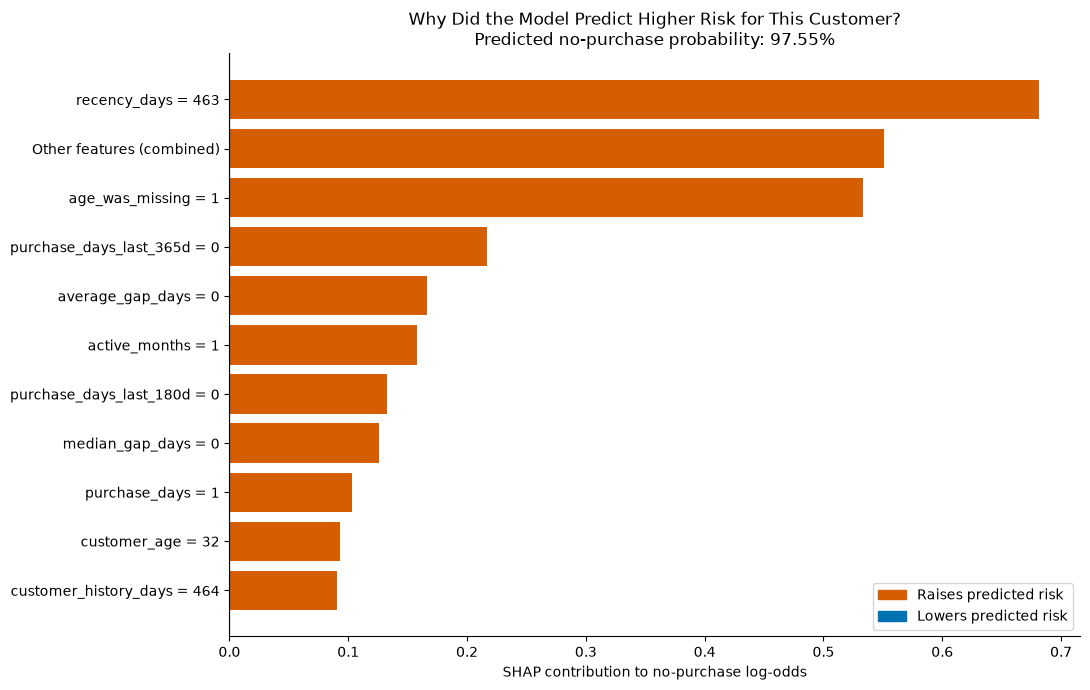

PASS: displayed contributions reconstruct this customer's prediction.


In [3]:
from matplotlib.patches import Patch

# Select by predicted risk, without using the future outcome.
example_position = int(np.argmax(no_purchase_probability))

example_probability = float(no_purchase_probability[example_position])
example_reference = float(reference_values[example_position])
example_contributions = feature_contributions[example_position]

individual_explanation = pd.DataFrame({
    "feature": explanation_features,
    "feature_value": X_explain.iloc[example_position].to_numpy(),
    "shap_log_odds": example_contributions,
})

individual_explanation["absolute_contribution"] = (
    individual_explanation["shap_log_odds"].abs()
)

individual_explanation = individual_explanation.sort_values(
    "absolute_contribution",
    ascending=False
).reset_index(drop=True)

individual_explanation["effect"] = np.select(
    [
        individual_explanation["shap_log_odds"] > 0,
        individual_explanation["shap_log_odds"] < 0,
    ],
    ["Raises predicted risk", "Lowers predicted risk"],
    default="No contribution"
)

print("Example: highest predicted-risk customer in the sample")
print("Historical feature cutoff: 2020-03-31")
print(f"Predicted probability of no purchase in the next 90 days: "
      f"{example_probability:.2%}")

print(
    f"Sigmoid of SHAP reference value: {expit(example_reference):.2%}"
)
print(
    "The reference above is a transformed model reference, "
    "not necessarily the average customer probability."
)

display(
    individual_explanation[
        ["feature", "feature_value", "shap_log_odds", "effect"]
    ].head(10).round(4)
)

# Preserve the complete explanation in the chart.
top_features = individual_explanation.head(10).copy()
other_contribution = float(
    individual_explanation.iloc[10:]["shap_log_odds"].sum()
)

plot_explanation = pd.DataFrame({
    "label": [
        f"{row.feature} = {row.feature_value:,.4g}"
        for row in top_features.itertuples()
    ] + ["Other features (combined)"],
    "contribution": (
        top_features["shap_log_odds"].tolist()
        + [other_contribution]
    )
})

plot_explanation = plot_explanation.sort_values("contribution")

colors = np.where(
    plot_explanation["contribution"] >= 0,
    "#D55E00",
    "#0072B2"
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    plot_explanation["label"],
    plot_explanation["contribution"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP contribution to no-purchase log-odds")
ax.set_title(
    "Why Did the Model Predict Higher Risk for This Customer?\n"
    f"Predicted no-purchase probability: {example_probability:.2%}"
)

ax.legend(handles=[
    Patch(color="#D55E00", label="Raises predicted risk"),
    Patch(color="#0072B2", label="Lowers predicted risk")
])

ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    explanation_report_dir / "higher_risk_customer_explanation.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Verify that top features plus the grouped remainder still reconstruct risk.
reconstructed_example_probability = float(expit(
    example_reference + plot_explanation["contribution"].sum()
))

assert np.isclose(
    reconstructed_example_probability,
    example_probability,
    rtol=1e-6,
    atol=1e-6
)

individual_explanation.to_csv(
    explanation_report_dir / "higher_risk_customer_feature_contributions.csv",
    index=False
)

print("PASS: displayed contributions reconstruct this customer's prediction.")

### Higher-Risk Customer Interpretation

The highest-risk customer in the sample received a predicted 90-day
no-purchase probability of 97.55%.

The customer had only one observed purchase day, with the last purchase
463 days before the cutoff. Recency and the absence of purchases during
recent windows contributed positively to the model's predicted risk.

The missing-age indicator also made a substantial positive contribution.
The displayed age of 32 was imputed and must not be interpreted as a
known customer attribute.

Zero average and median purchase gaps are placeholders for an unavailable
gap history because the customer had only one purchase day.

These contributions explain the model output, not the causes of inactivity.
The prediction concerns the next 90 days and does not establish permanent churn.

Example: lowest predicted-risk customer in the sample
Predicted 90-day no-purchase probability: 1.49%


,feature,feature_value,shap_log_odds,effect
0,recency_days,1.0000,-0.7593,Lowers predicted risk
1,active_months,18.0000,-0.7087,Lowers predicted risk
2,purchase_days_last_365d,26.0000,-0.4145,Lowers predicted risk
3,purchase_days_last_180d,14.0000,-0.3902,Lowers predicted risk
4,purchase_days_last_30d,5.0000,-0.3893,Lowers predicted risk
5,purchase_days_recent_90d,8.0000,-0.3823,Lowers predicted risk
6,purchase_days,39.0000,-0.3625,Lowers predicted risk
7,completed_purchase_gaps,38.0000,-0.3507,Lowers predicted risk
8,purchase_days_last_90d,8.0000,-0.3168,Lowers predicted risk
9,average_gap_days,14.2895,-0.1533,Lowers predicted risk


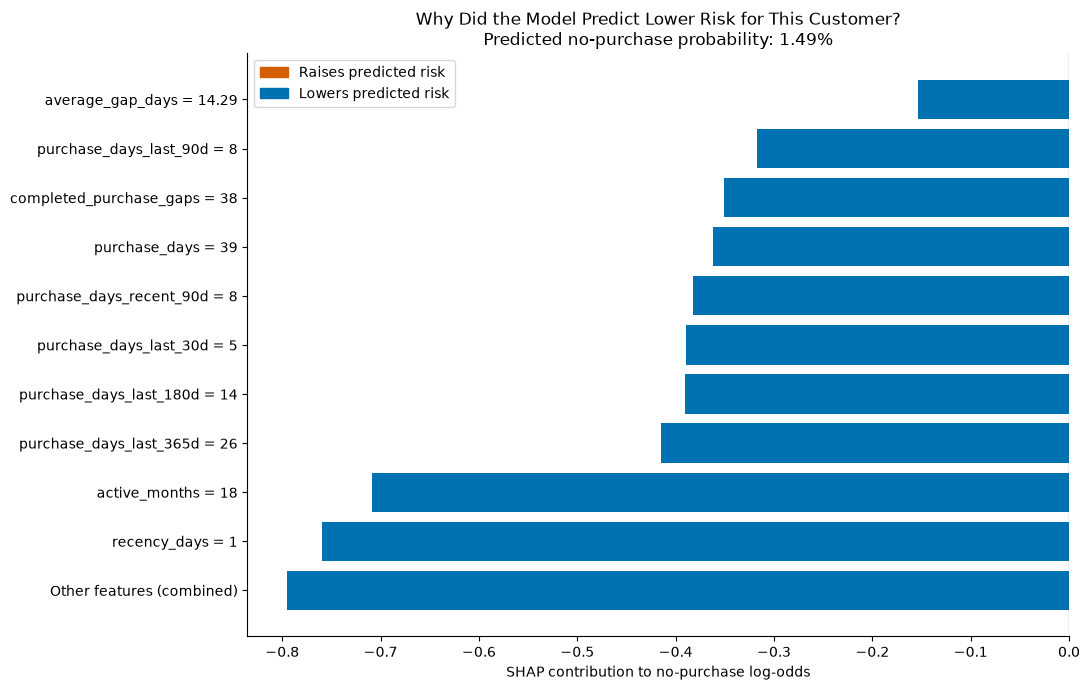

PASS: displayed contributions reconstruct the lower-risk prediction.


In [4]:
# Select the lowest predicted risk without using the actual future outcome.
low_risk_position = int(np.argmin(no_purchase_probability))

low_risk_probability = float(
    no_purchase_probability[low_risk_position]
)
low_risk_reference = float(reference_values[low_risk_position])

low_risk_explanation = pd.DataFrame({
    "feature": explanation_features,
    "feature_value": X_explain.iloc[low_risk_position].to_numpy(),
    "shap_log_odds": feature_contributions[low_risk_position],
})

low_risk_explanation["absolute_contribution"] = (
    low_risk_explanation["shap_log_odds"].abs()
)

low_risk_explanation = low_risk_explanation.sort_values(
    "absolute_contribution", ascending=False
).reset_index(drop=True)

low_risk_explanation["effect"] = np.select(
    [
        low_risk_explanation["shap_log_odds"] > 0,
        low_risk_explanation["shap_log_odds"] < 0,
    ],
    ["Raises predicted risk", "Lowers predicted risk"],
    default="No contribution"
)

print("Example: lowest predicted-risk customer in the sample")
print(f"Predicted 90-day no-purchase probability: {low_risk_probability:.2%}")

display(
    low_risk_explanation[
        ["feature", "feature_value", "shap_log_odds", "effect"]
    ].head(10).round(4)
)

top_features = low_risk_explanation.head(10)

low_risk_plot = pd.DataFrame({
    "label": [
        f"{row.feature} = {row.feature_value:,.4g}"
        for row in top_features.itertuples()
    ] + ["Other features (combined)"],
    "contribution": (
        top_features["shap_log_odds"].tolist()
        + [float(low_risk_explanation.iloc[10:]["shap_log_odds"].sum())]
    )
}).sort_values("contribution")

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    low_risk_plot["label"],
    low_risk_plot["contribution"],
    color=np.where(
        low_risk_plot["contribution"] >= 0,
        "#D55E00", "#0072B2"
    )
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP contribution to no-purchase log-odds")
ax.set_title(
    "Why Did the Model Predict Lower Risk for This Customer?\n"
    f"Predicted no-purchase probability: {low_risk_probability:.2%}"
)
ax.legend(handles=[
    Patch(color="#D55E00", label="Raises predicted risk"),
    Patch(color="#0072B2", label="Lowers predicted risk")
])
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    explanation_report_dir / "lower_risk_customer_explanation.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

assert np.isclose(
    expit(low_risk_reference + low_risk_plot["contribution"].sum()),
    low_risk_probability,
    rtol=1e-6,
    atol=1e-6
)

low_risk_explanation.to_csv(
    explanation_report_dir / "lower_risk_customer_feature_contributions.csv",
    index=False
)

print("PASS: displayed contributions reconstruct the lower-risk prediction.")

### Lower-Risk Customer Interpretation

The lowest-risk customer in the sample received a predicted 90-day
no-purchase probability of 1.49%.

The customer purchased one day before the cutoff, had activity in
18 distinct months, and purchased on 26 days during the previous year.
These features contributed toward lower predicted risk.

Their 39 observed purchase days produced 38 completed purchase gaps,
with an average gap of approximately 14.29 days.

The two 90-day purchase-frequency features represent the same information.
Their SHAP contributions should be considered together rather than treated
as independent evidence.

The higher- and lower-risk customers are illustrative extremes selected
from the sample. They do not represent the whole customer population,
and their predicted probabilities are not guarantees of future behavior.

In [5]:
import json
import hashlib
from datetime import datetime, timezone

# Stable IDs preserve alignment between inputs, predictions, and explanations.
sample_customer_ids = explanation_sample["customer_id"].to_numpy()

explanation_sample_scores = pd.DataFrame({
    "customer_id": sample_customer_ids,
    "feature_cutoff": "2020-03-31",
    "predicted_no_purchase_probability": no_purchase_probability,
    "raw_model_output": raw_model_output,
    "shap_reference_log_odds": reference_values,
})

# Save the exact float32 inputs used for the explanations.
explanation_inputs_export = X_explain.reset_index(drop=True).copy()
explanation_inputs_export.insert(0, "customer_id", sample_customer_ids)

# Long format: one row per customer and feature.
explanation_contributions_export = pd.DataFrame({
    "customer_id": np.repeat(
        sample_customer_ids, len(explanation_features)
    ),
    "feature_position": np.tile(
        np.arange(len(explanation_features)), len(sample_customer_ids)
    ),
    "feature": np.tile(
        explanation_features, len(sample_customer_ids)
    ),
    "feature_value": X_explain.to_numpy().ravel(),
    "shap_log_odds": feature_contributions.ravel(),
})

assert explanation_sample_scores["customer_id"].is_unique
assert len(explanation_contributions_export) == 500 * 26
assert not explanation_contributions_export.duplicated(
    ["customer_id", "feature"]
).any()

export_tables = {
    "sample_scores.parquet": explanation_sample_scores,
    "sample_inputs.parquet": explanation_inputs_export,
    "sample_shap_contributions.parquet": explanation_contributions_export,
}

export_summary = []

# DuckDB writes Parquet without requiring an additional pandas engine.
with duckdb.connect() as export_con:
    for filename, dataframe in export_tables.items():
        output_path = explanation_report_dir / filename
        sql_path = output_path.as_posix().replace("'", "''")

        export_con.register("explanation_export", dataframe)
        export_con.execute(f"""
            COPY explanation_export
            TO '{sql_path}'
            (FORMAT PARQUET, COMPRESSION ZSTD)
        """)
        export_con.unregister("explanation_export")

        saved_count = export_con.execute(
            "SELECT COUNT(*) FROM read_parquet(?)",
            [str(output_path)]
        ).fetchone()[0]

        assert saved_count == len(dataframe)

        export_summary.append({
            "file": filename,
            "verified_rows": saved_count,
            "size_KiB": output_path.stat().st_size / 1024
        })

explanation_metadata = {
    "model_file": str(churn_model_path.relative_to(project_root)),
    "model_sha256": hashlib.sha256(churn_model_path.read_bytes()).hexdigest(),
    "feature_cutoff": "2020-03-31",
    "prediction_horizon_days": 90,
    "positive_class": 1,
    "positive_class_meaning": "No observed purchase in the next 90 days",
    "sample_size": len(explanation_sample),
    "sampling_rule": "ORDER BY MD5(customer_id), customer_id LIMIT 500",
    "feature_order": explanation_features,
    "input_dtype": "float32",
    "explanation_method": "CatBoost native ShapValues",
    "contribution_units": "log-odds",
    "probability_formula": "sigmoid(reference + sum(feature contributions))",
    "catboost_version": catboost.__version__,
    "examples": {
        "highest_sample_risk_customer_id": str(
            sample_customer_ids[example_position]
        ),
        "lowest_sample_risk_customer_id": str(
            sample_customer_ids[low_risk_position]
        ),
    },
    "limitations": [
        "Explanations describe model associations, not causal effects.",
        "Sample importance is not full-population importance.",
        "Two 90-day purchase-frequency features duplicate information.",
        "Customer snapshot availability at the historical cutoff is unverified.",
        "Imputed age and zero-filled unavailable gap statistics require context."
    ],
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

(explanation_report_dir / "explanation_metadata.json").write_text(
    json.dumps(explanation_metadata, indent=2, allow_nan=False),
    encoding="utf-8"
)

display(pd.DataFrame(export_summary).round(2))
print("Saved explanations:", explanation_report_dir)

,file,verified_rows,size_KiB
0,sample_scores.parquet,500,25.63
1,sample_inputs.parquet,500,38.18
2,sample_shap_contributions.parquet,13000,137.67


Saved explanations: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\churn_explanations
